# Tarea 2 · Deep Learning (CIT3360) — Ítem 2: YOLO con transfer learning

> **Variante 80/10/10.** Copia de `../03_yolo_preentrenado.ipynb` que entrena y evalúa con la partición 80/10/10 de esta carpeta (train 2400, val 301 y test 301 imágenes; huella `84ea7ae5b688`). Solo cambian las rutas, la huella y los textos que dependen de la partición: el diseño, los hiperparámetros y las decisiones del grupo son los del original, salvo el NMS de la evaluación: IoU 0,5 en vez de 0,7 (`IOU_NMS`, cambio del 9 de noviembre de 2026; el entrenamiento no se repitió). Los pesos y registros van a `~/tarea2_runs_80_10_10/`.

Detector **YOLOv8n** (Ultralytics) inicializado con **pesos preentrenados en COCO** y ajustado a FjordFish con *fine-tuning* completo. Se usan la misma arquitectura base, los mismos hiperparámetros, el mismo aumento de datos y las mismas particiones que `02_yolo_desde_cero.ipynb`: la diferencia entre ambos cuadernos es el punto de partida de los pesos, que además deja la rama de clases un poco más ancha (sección 3).

**Ítems de la rúbrica**
- 2.1 (YOLO con pesos COCO): secciones 3 a 7.
- 2.2 (qué se congeló, qué se entrenó y si hubo *fine-tuning*): sección 5.
- 2.3 (justificación de hiperparámetros, épocas y aumento de datos): sección 13.
- 2.4 (comparación con los modelos desde cero): `05_comparacion.ipynb`, con los archivos que deja la sección 12.

**Decisiones del grupo que usa este cuaderno** (`PLAN_TAREA2.md` §4)
- Entrada de 640 px con *letterbox* (D3), el mismo aumento de datos en todos los modelos, sin mosaico (D5), y las 28 categorías de `data.yaml` (D6).
- *Fine-tuning* completo con `yolov8n` (D7), con las mismas épocas, paciencia, tasa de aprendizaje y criterio de parada que YOLO desde cero.

**Contenido**
0. Entorno · 1. Configuración · 2. Verificación de las particiones · 3. Arquitectura y pesos COCO · 4. Entrenamiento · 5. Qué se congeló y qué se entrenó · 6. Curvas de entrenamiento · 7. Evaluación (Ultralytics) · 8. Eficiencia · 9. Resultados cualitativos · 10. Predicciones de validación y test · 11. Métricas con el evaluador común · 12. Resumen para la comparación · 13–14. Justificación y análisis (grupo) · Declaración de uso de IA

> **Nota:** la primera vez, Ultralytics descarga `yolov8n.pt` (los pesos COCO) y `yolo26n.pt`. Este último solo sirve para comprobar que la precisión mixta funciona en la GPU; no se usa para entrenar.

## 0. Entorno

Requiere `ultralytics`, PyTorch con CUDA (ver `requirements.txt`) y `comun.py` en la misma carpeta que el cuaderno. En Windows, `torchvision` debe ser la versión con CUDA que corresponde a la versión instalada de PyTorch.

In [1]:
import json
import time
import random
import platform
from importlib.util import find_spec
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import yaml
from PIL import Image
import ultralytics
from ultralytics import YOLO
from ultralytics.nn.tasks import DetectionModel
from ultralytics.utils.torch_utils import get_flops

from comun import cargar_particiones, verificar_huella, cargar_cajas_reales, evaluar_detecciones, CARPETA_RUNS

print("Python      :", platform.python_version())
print("PyTorch     :", torch.__version__, "| CUDA disponible:", torch.cuda.is_available())
print("Ultralytics :", ultralytics.__version__)
if torch.cuda.is_available():
    print("GPU         :", torch.cuda.get_device_name(0))
# Con albumentations instalado, Ultralytics agrega aumentos (desenfoque, CLAHE, gris) que la CNN propia no tiene
assert find_spec("albumentations") is None, "Desinstalar albumentations para que YOLO y la CNN usen el mismo aumento (D5)"
DISPOSITIVO = 0 if torch.cuda.is_available() else "cpu"

Python      : 3.14.0
PyTorch     : 2.14.0+cu130 | CUDA disponible: True
Ultralytics : 8.4.192
GPU         : NVIDIA GeForce RTX 4060 Laptop GPU


In [2]:
# Estilo de los gráficos: colores categóricos en orden fijo (azul, naranja, aqua) y ejes discretos
AZUL, NARANJA, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#898781"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False, "figure.dpi": 100,
})

## 1. Configuración del experimento

Todos los parámetros del experimento están en esta celda. Son los mismos de `02_yolo_desde_cero.ipynb`; cambian los pesos iniciales (`PESOS_COCO`) y el argumento `pretrained=True` de la llamada a `train`. La arquitectura es la misma salvo la rama de clasificación (`cv3`), cuyas capas tienen 80 canales en el preentrenado y 64 en el de desde cero. Son 128.256 parámetros de diferencia.

| Parámetro | Qué controla |
|---|---|
| `MODELO_YAML`, `PESOS_COCO` | arquitectura de la red y pesos preentrenados en COCO (D7) |
| `freeze` | capas congeladas; `None` = *fine-tuning* completo (D7) |
| `epochs`, `patience` | máximo de épocas; parada temprana si el mAP50-95 de validación no mejora en `patience` épocas |
| `imgsz`, `batch` | lado de la imagen de entrada (px) y tamaño de lote (los gradientes se acumulan hasta un lote nominal de 64) |
| `optimizer`, `lr0`, `lrf`, `momentum`, `warmup_epochs`, `cos_lr` | optimizador y programa de la tasa de aprendizaje (decae de `lr0` a `lr0·lrf`; lineal o coseno) |
| `weight_decay` | regularización L2 |
| `cls_pw` | ponderación de clases inversa a su frecuencia (0 = desactivada) |
| `hsv_*`, `degrees`, `translate`, `scale`, `shear`, `perspective`, `flipud`, `fliplr`, `mosaic`, `mixup`, `cutmix` | aumento de datos (magnitudes y probabilidades), el mismo en todos los modelos (D5) |
| `N_IMAGENES_VELOCIDAD`, `N_EJEMPLOS` | imágenes para medir la velocidad y para los ejemplos cualitativos |
| `UMBRAL_CONFIANZA` | confianza mínima de las detecciones que se dibujan y de la medición de velocidad (umbral común que fijó el grupo, D8) |

Con `PRUEBA_RAPIDA = True` se entrena 3 épocas con el 10 % de train y las salidas van a `pruebas/`, sin pisar los resultados reales. Con `ENTRENAR = False` se reutiliza el entrenamiento guardado.

Los pesos y registros del entrenamiento se guardan en `~/tarea2_runs_80_10_10/` (`CARPETA_RUNS` de `comun.py`), fuera de OneDrive. Las tablas y figuras van en `resultados/yolo_preentrenado/`.

In [3]:
RAIZ = Path.cwd()
PRUEBA_RAPIDA = False     # True: 3 épocas con el 10 % de train para probar el flujo completo
ENTRENAR = False          # False: reutiliza el entrenamiento guardado en RUN_EXISTENTE

DATA_YAML = RAIZ / "datasets" / "fjordfish" / "fjordfish.yaml"
DIR_DATASET = DATA_YAML.parent
DIR_SPLITS = RAIZ / "splits"
DIR_BASE = RAIZ / "pruebas" if PRUEBA_RAPIDA else RAIZ        # las pruebas no pisan los resultados reales
DIR_RUNS = CARPETA_RUNS / ("pruebas" if PRUEBA_RAPIDA else "reales") / "yolo_preentrenado"   # pesos y registros, fuera de OneDrive
DIR_RESULTADOS = DIR_BASE / "resultados" / "yolo_preentrenado"   # tablas y figuras para la presentación
RUN_EXISTENTE = DIR_RUNS / "entrenamiento"

SEMILLA = 42
MODELO_YAML = "yolov8n.yaml"   # la misma arquitectura de YOLO desde cero (D7)
PESOS_COCO = "yolov8n.pt"      # pesos preentrenados en COCO

HIPERPARAMETROS = dict(
    freeze=None,           # D7: fine-tuning completo, no se congela ninguna capa
    epochs=300,
    patience=50,
    imgsz=640,
    batch=16,
    optimizer="SGD",
    lr0=0.01,
    lrf=0.01,
    momentum=0.937,
    weight_decay=5e-4,
    warmup_epochs=3.0,
    cos_lr=False,
    close_mosaic=0,        # sin mosaico (D5): no hay nada que desactivar al final
    cls_pw=0.0,
)
AUMENTO_DATOS = dict(      # el mismo de todos los modelos (D5)
    hsv_h=0.015, hsv_s=0.7, hsv_v=0.4,
    degrees=0.0, translate=0.1, scale=0.5, shear=0.0, perspective=0.0,
    flipud=0.0, fliplr=0.5,
    mosaic=0.0, mixup=0.0, cutmix=0.0,
)
UMBRAL_CONFIANZA = 0.25   # D8: umbral común que fijó el grupo con validación
IOU_NMS = 0.5             # IoU del NMS al evaluar: el protocolo común de esta variante (Ultralytics usa 0,7)
N_IMAGENES_VELOCIDAD = 200  # imágenes de test para medir la velocidad
N_EJEMPLOS = 4            # imágenes de test de los ejemplos cualitativos
WORKERS = 8               # procesos de carga de datos
FRACCION_TRAIN = 1.0

if PRUEBA_RAPIDA:
    HIPERPARAMETROS.update(epochs=3, patience=3)
    FRACCION_TRAIN = 0.1

random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)

## 2. Verificación del dataset y de las particiones

Se comprueba que las carpetas del dataset coinciden con `splits/*.txt` y que la **huella** de las particiones es la común del grupo (`84ea7ae5b688`). Si no coincide, el cuaderno se detiene: así se garantiza que todos los modelos usan las mismas particiones.

In [4]:
assert DATA_YAML.exists(), "Primero hay que ejecutar 00_preparacion_dataset.ipynb"
datos = yaml.safe_load(DATA_YAML.read_text(encoding="utf-8"))
NOMBRES = datos["names"]
particion, huella = cargar_particiones(DIR_SPLITS)
verificar_huella(huella)

filas = []
for s, ids in particion.items():
    en_disco = {p.stem for p in (DIR_DATASET / datos[s]).glob("*.jpg")}
    assert en_disco == set(ids), f"images/{s} no coincide con splits/{s}.txt"
    n_cajas = sum(len((DIR_DATASET / "labels" / s / f"{i}.txt").read_text().splitlines()) for i in ids)
    filas.append({"partición": s, "imágenes": len(ids), "cajas": n_cajas})
print(f"{len(NOMBRES)} clases | huella de la partición: {huella} (verificada)")
pd.DataFrame(filas).set_index("partición")

28 clases | huella de la partición: 84ea7ae5b688 (verificada)


,imágenes,cajas
partición,,
train,2400,5076
val,301,622
test,301,649


## 3. Arquitectura y pesos COCO

La arquitectura es la de `02_yolo_desde_cero.ipynb` (`yolov8n`): un detector de una etapa y sin anclas, con **backbone** (extrae características), **neck** (combina escalas) y **head** (una rama predice las cajas y otra las clases, en tres escalas).

COCO tiene 80 clases y FjordFish 28. El ancho de la rama de clases depende del número de clases, así que YOLO desde cero la construye con 64 canales. Al cargar `yolov8n.pt`, Ultralytics la reconstruye con los 80 canales de COCO para poder transferir sus capas ocultas, y solo crea de nuevo la última capa, con 28 salidas. Por eso este modelo tiene 3,14 M de parámetros y YOLO desde cero 3,02 M. La celda siguiente hace el mismo paso que el entrenamiento y cuenta los parámetros y los GFLOPs del modelo real; la sección 5 muestra qué se transfirió.

In [5]:
red = DetectionModel(MODELO_YAML, nc=len(NOMBRES), verbose=False)
red.load(YOLO(PESOS_COCO).model)      # el mismo paso del entrenamiento: copia los pesos COCO que calzan
red.info(verbose=True, imgsz=HIPERPARAMETROS["imgsz"])
n_parametros = sum(p.numel() for p in red.parameters())
gflops = get_flops(red, imgsz=HIPERPARAMETROS["imgsz"])
del red

Overriding model.yaml nc=80 with nc=28


Transferred 349/355 items from pretrained weights


YOLOv8n summary: 130 layers, 3,144,564 parameters, 3,144,548 gradients, 8.8 GFLOPs


## 4. Entrenamiento

`YOLO(PESOS_COCO)` con `pretrained=True` parte de los pesos COCO y `freeze=None` deja entrenar todas las capas (*fine-tuning* completo). Ultralytics guarda en `~/tarea2_runs_80_10_10/reales/yolo_preentrenado/entrenamiento/`: `weights/best.pt` (época con mayor mAP50-95 en validación), `weights/last.pt`, `results.csv` y gráficos.

Al iniciar el entrenamiento, una función registra el estado real de cada parámetro en `componentes.csv`, para la tabla de la sección 5.

In [6]:
def componente_de(nombre):
    """Componente de YOLOv8 al que pertenece un parámetro: en yolov8n, capas 0-9 backbone, 10-21 neck y 22 head."""
    capa = int(nombre.split(".")[1])
    if capa <= 9:
        return "Backbone (capas 0-9)"
    if capa <= 21:
        return "Neck (capas 10-21)"
    return {"cv2": "Head: rama de cajas", "cv3": "Head: rama de clases", "dfl": "Head: DFL"}[nombre.split(".")[2]]


def tabla_de_componentes(red, pesos_coco):
    """Por componente: parámetros, cuántos se entrenan y cuántos conservan su valor de COCO."""
    filas = {}
    for nombre, p in red.named_parameters():
        fila = filas.setdefault(componente_de(nombre), dict.fromkeys(["parámetros", "entrenables", "congelados", "desde COCO", "nuevos"], 0))
        coco = pesos_coco.get(nombre)
        desde_coco = coco is not None and coco.shape == p.shape and torch.equal(coco.to(p.device, p.dtype), p)
        fila["parámetros"] += p.numel()
        fila["entrenables" if p.requires_grad else "congelados"] += p.numel()
        fila["desde COCO" if desde_coco else "nuevos"] += p.numel()
    return pd.DataFrame(filas).T.rename_axis("componente")

El entrenamiento, con los mismos hiperparámetros y el mismo aumento de datos de YOLO desde cero. Solo cambian los pesos iniciales.

In [7]:
if ENTRENAR:
    modelo = YOLO(PESOS_COCO)             # parte de los pesos preentrenados en COCO
    pesos_coco = {k: v.float() for k, v in modelo.model.state_dict().items()}
    # Se registra al iniciar, cuando Ultralytics ya copió los pesos COCO y aplicó `freeze`
    modelo.add_callback("on_train_start", lambda entrenador: tabla_de_componentes(entrenador.model, pesos_coco)
                        .to_csv(Path(entrenador.save_dir) / "componentes.csv"))
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    inicio = time.perf_counter()
    modelo.train(
        data=str(DATA_YAML),
        pretrained=True,
        device=DISPOSITIVO,
        seed=SEMILLA,
        deterministic=True,
        fraction=FRACCION_TRAIN,
        workers=WORKERS,
        project=str(DIR_RUNS),
        name="entrenamiento",
        exist_ok=True,            # siempre la misma carpeta: RUN_EXISTENTE sigue siendo válido
        plots=True,
        **HIPERPARAMETROS,
        **AUMENTO_DATOS,
    )
    tiempo_entrenamiento_s = time.perf_counter() - inicio
    RUN_DIR = Path(modelo.trainer.save_dir)
    info_entrenamiento = {
        "modelo": PESOS_COCO,
        "tiempo_entrenamiento_s": round(tiempo_entrenamiento_s, 1),
        "memoria_gpu_max_GB": round(torch.cuda.max_memory_reserved() / 1e9, 2) if torch.cuda.is_available() else None,
        "dispositivo": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
        "hiperparametros": HIPERPARAMETROS,
        "aumento_datos": AUMENTO_DATOS,
        "fraccion_train": FRACCION_TRAIN,
        "semilla": SEMILLA,
        "huella_particion": huella,
    }
    (RUN_DIR / "info_entrenamiento.json").write_text(json.dumps(info_entrenamiento, indent=2), encoding="utf-8")
    del modelo
else:
    RUN_DIR = Path(RUN_EXISTENTE)
    info_entrenamiento = json.loads((RUN_DIR / "info_entrenamiento.json").read_text(encoding="utf-8"))

PESOS = RUN_DIR / "weights" / "best.pt"
print("Entrenamiento:", RUN_DIR)
print(f"Tiempo total de entrenamiento: {info_entrenamiento['tiempo_entrenamiento_s'] / 60:.1f} min")

Entrenamiento: C:\Users\rslat\tarea2_runs_80_10_10\reales\yolo_preentrenado\entrenamiento
Tiempo total de entrenamiento: 88.7 min


Un lote de entrenamiento tal como lo ve la red, con el mismo aumento de datos de los otros modelos.

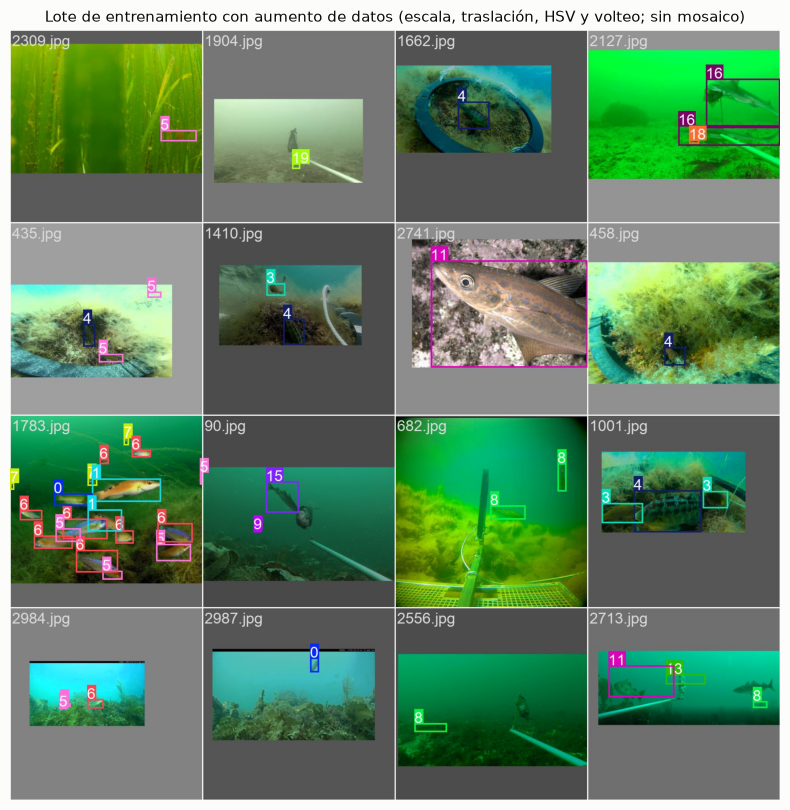

In [8]:
# Lote de entrenamiento tal como lo ve la red (letterbox + aumento de datos, sin mosaico)
ruta_lote = RUN_DIR / "train_batch0.jpg"
if ruta_lote.exists():
    plt.figure(figsize=(10, 10))
    plt.imshow(Image.open(ruta_lote))
    plt.title("Lote de entrenamiento con aumento de datos (escala, traslación, HSV y volteo; sin mosaico)")
    plt.axis("off")
    plt.show()

## 5. Qué se congeló y qué se entrenó (ítem 2.2)

La tabla sale del modelo real al iniciar el entrenamiento, no de la configuración:
- **entrenables / congelados:** parámetros que se actualizan o que quedan fijos. Hubo *fine-tuning* en todo lo entrenable que viene de COCO.
- **desde COCO / nuevos:** parámetros que conservan el valor de `yolov8n.pt` o que parten con pesos aleatorios. Los nuevos son la última capa de la rama de clases, cuya salida depende del número de clases.

La capa DFL queda siempre congelada en Ultralytics: es una convolución fija que convierte distribuciones en distancias, no una capa que aprenda.

In [9]:
tabla_componentes = pd.read_csv(RUN_DIR / "componentes.csv", index_col="componente")
congelados_fuera_de_dfl = tabla_componentes.drop(index="Head: DFL").congelados.sum()
assert congelados_fuera_de_dfl == 0, "Con fine-tuning completo solo la capa DFL debería quedar congelada"
tabla_componentes.loc["Total"] = tabla_componentes.sum()
tabla_componentes.to_csv(DIR_RESULTADOS / "componentes.csv")
tabla_componentes

,parámetros,entrenables,congelados,desde COCO,nuevos
componente,,,,,
Backbone (capas 0-9),1272656,1272656,0,1272656,0
Neck (capas 10-21),986880,986880,0,986880,0
Head: rama de cajas,381888,381888,0,381888,0
Head: rama de clases,503124,503124,0,496320,6804
Head: DFL,16,0,16,16,0
Total,3144564,3144548,16,3137760,6804


## 6. Curvas de entrenamiento

Pérdidas de entrenamiento y validación por época y métricas de validación. La línea discontinua marca la época de `best.pt`.

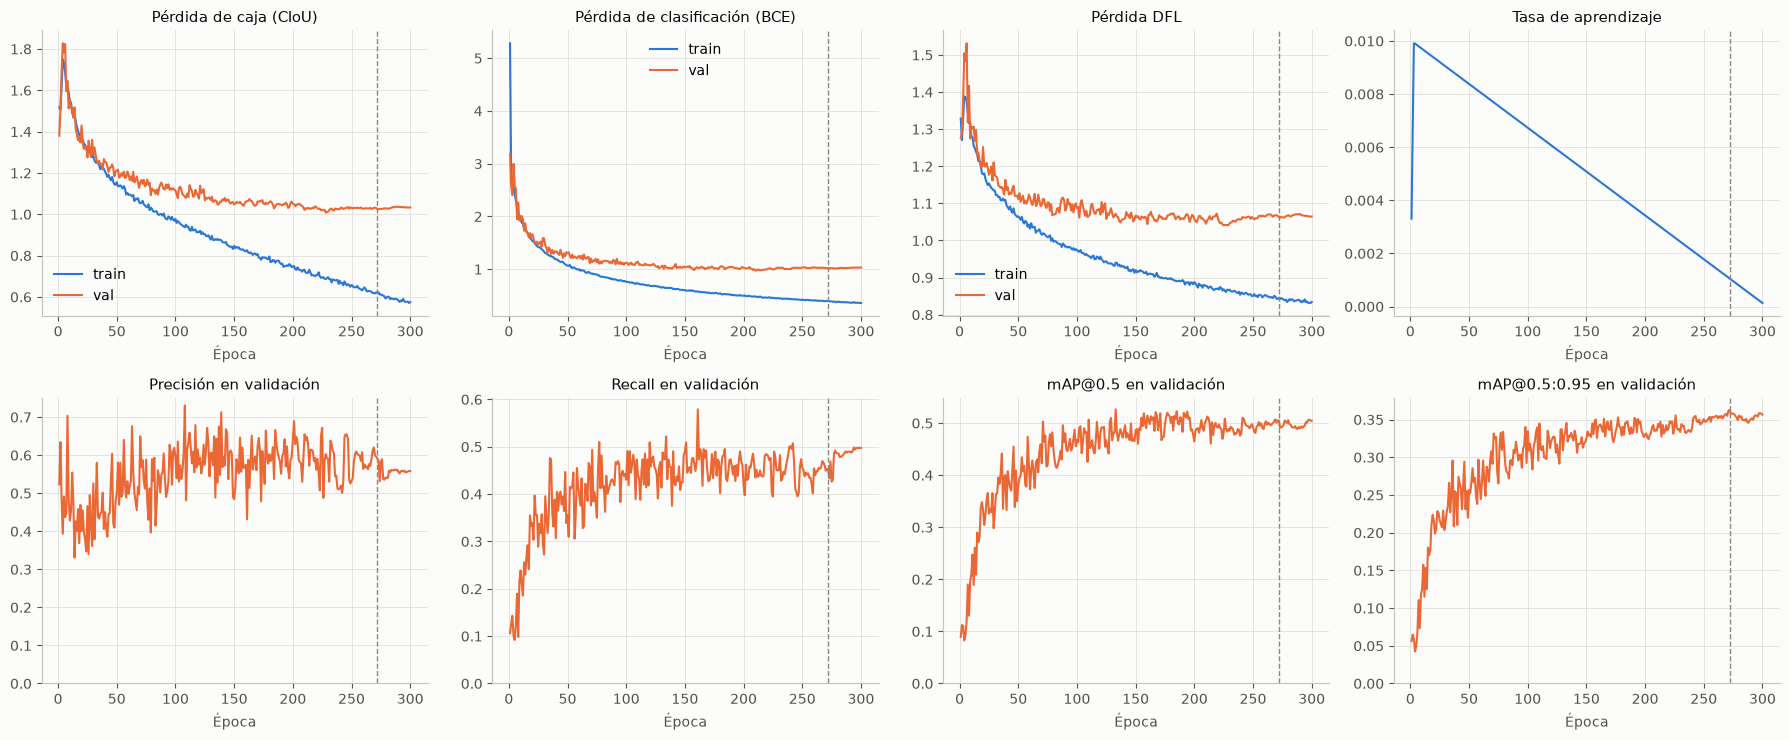

Épocas ejecutadas: 300 | mejor época: 272 | tiempo medio por época: 17.7 s


In [10]:
hist = pd.read_csv(RUN_DIR / "results.csv")
hist.columns = hist.columns.str.strip()
epocas_ejecutadas = int(hist.epoch.max())
mejor_epoca = int(hist.loc[hist["metrics/mAP50-95(B)"].idxmax(), "epoch"])
tiempo_por_epoca_s = float(hist.time.iloc[-1] / len(hist))

perdidas = [("box_loss", "Pérdida de caja (CIoU)"), ("cls_loss", "Pérdida de clasificación (BCE)"), ("dfl_loss", "Pérdida DFL")]
metricas = [("metrics/precision(B)", "Precisión"), ("metrics/recall(B)", "Recall"),
            ("metrics/mAP50(B)", "mAP@0.5"), ("metrics/mAP50-95(B)", "mAP@0.5:0.95")]

fig, axes = plt.subplots(2, 4, figsize=(18, 7.5))
for ax, (clave, titulo) in zip(axes[0], perdidas):
    ax.plot(hist.epoch, hist[f"train/{clave}"], color=AZUL, lw=1.5, label="train")
    ax.plot(hist.epoch, hist[f"val/{clave}"], color=NARANJA, lw=1.5, label="val")
    ax.set_title(titulo)
    ax.legend()
axes[0, 3].plot(hist.epoch, hist["lr/pg0"], color=AZUL, lw=1.5)
axes[0, 3].set_title("Tasa de aprendizaje")
for ax, (clave, titulo) in zip(axes[1], metricas):
    ax.plot(hist.epoch, hist[clave], color=NARANJA, lw=1.5)
    ax.set_title(f"{titulo} en validación")
    ax.set_ylim(0, None)
for ax in axes.flat:
    ax.set_xlabel("Época")
    ax.axvline(mejor_epoca, color=GRIS, ls="--", lw=1)
fig.tight_layout()
fig.savefig(DIR_RESULTADOS / "curvas_entrenamiento.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Épocas ejecutadas: {epocas_ejecutadas} | mejor época: {mejor_epoca} | tiempo medio por época: {tiempo_por_epoca_s:.1f} s")

## 7. Evaluación en validación y test (métricas de Ultralytics)

Se evalúa `best.pt` (elegido por mAP50-95 en validación) en val y, una sola vez, en test. Métricas de Ultralytics:

- **Precisión y recall** medios entre clases, al umbral de confianza que maximiza el F1 medio; **F1** = 2PR/(P+R).
- **mAP@0.5**, **mAP@0.75** y **mAP@0.5:0.95** (COCO): AP por clase promediado entre las clases con instancias en el conjunto evaluado.
- Para el mAP se usa `conf = 0.001` e IoU de NMS 0,5 (`IOU_NMS`), el protocolo común de esta variante; el valor estándar de Ultralytics es 0,7.

La comparación entre modelos no usa estas métricas, sino las del evaluador común de `comun.py` (sección 11), que calcula todo igual para todos los modelos.

In [11]:
mejor = YOLO(PESOS)
args_eval = dict(data=str(DATA_YAML), imgsz=HIPERPARAMETROS["imgsz"], batch=HIPERPARAMETROS["batch"],
                 conf=0.001, iou=IOU_NMS, device=DISPOSITIVO, project=str(DIR_RUNS), plots=True,
                 save_json=True)   # guarda las detecciones de la evaluación (sección 10)
met = {
    "val": mejor.val(split="val", name="evaluacion_val", **args_eval),
    "test": mejor.val(split="test", name="evaluacion_test", **args_eval),
}


def resumen_metricas(m):
    p, r = float(m.box.mp), float(m.box.mr)
    return {"precision": p, "recall": r, "F1": 2 * p * r / (p + r + 1e-16),
            "mAP50": float(m.box.map50), "mAP75": float(m.box.map75), "mAP50_95": float(m.box.map)}


tabla_global = pd.DataFrame({s: resumen_metricas(m) for s, m in met.items()}).T
tabla_global.to_csv(DIR_RESULTADOS / "metricas_val_test.csv")
tabla_global.round(4)

Ultralytics 8.4.192  Python-3.14.0 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)


Model summary (fused): 73 layers, 3,139,268 parameters, 0 gradients, 8.7 GFLOPs


val: Fast image access  (ping: 0.0±0.0 ms, read: 1370.9±160.5 MB/s, size: 225.9 KB)


val: Scanning C:\Users\rslat\OneDrive\Escritorio\TareaDL2\particion_80_10_10\datasets\fjordfish\labels\val.cache... 301 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 301/301 63.1Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 5% ╸─────────── 1/19 65.5s/it 19.6s<19:38

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 10% ━─────────── 2/19 1.6it/s 19.8s<10.9s

... (131 outputs left out)

 Average Recall     (AR) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.639


 Average Recall     (AR) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.503


Results saved to C:\Users\rslat\tarea2_runs_80_10_10\reales\yolo_preentrenado\evaluacion_test-2


,precision,recall,F1,mAP50,mAP75,mAP50_95
val,0.5880,0.4371,0.5014,0.4940,0.3978,0.3602
test,0.5461,0.4516,0.4944,0.4728,0.3762,0.3388


Métricas por clase en test, según Ultralytics.

In [12]:
# Métricas por clase en test (solo aparecen las clases con instancias en test)
por_clase = pd.DataFrame(met["test"].summary())
por_clase.to_csv(DIR_RESULTADOS / "metricas_por_clase_test.csv", index=False)
por_clase.sort_values("Instances", ascending=False).reset_index(drop=True)

,Class,Images,Instances,Box-P,Box-R,Box-F1,mAP50,mAP75,mAP50-95
0,goldsinny,80,159,0.69589,0.67925,0.68747,0.65754,0.47973,0.42795
1,corkwing_male,115,117,0.86077,0.89826,0.87911,0.89713,0.66667,0.63250
2,cod,63,87,0.86872,0.81609,0.84158,0.83527,0.68769,0.63482
3,spiny_dogfish,33,51,0.93477,0.84298,0.88651,0.83470,0.50618,0.54370
4,corkwing_female,38,51,0.70764,0.56863,0.63056,0.64649,0.57360,0.48912
5,gadines_unknown,10,36,0.93294,0.47222,0.62705,0.59846,0.47851,0.39284
6,labrids_unknown,21,34,0.36124,0.32353,0.34135,0.22113,0.10273,0.11423
7,brown_crab,11,18,0.68612,0.33333,0.44869,0.42008,0.17573,0.20138
8,cod_yoy,12,14,0.66881,0.50000,0.57221,0.50971,0.41971,0.35705
9,pollack,12,13,0.28407,0.23077,0.25466,0.19107,0.19107,0.12156


El mismo AP50 por clase como gráfico, de menor a mayor, con el número de instancias de cada clase en test.

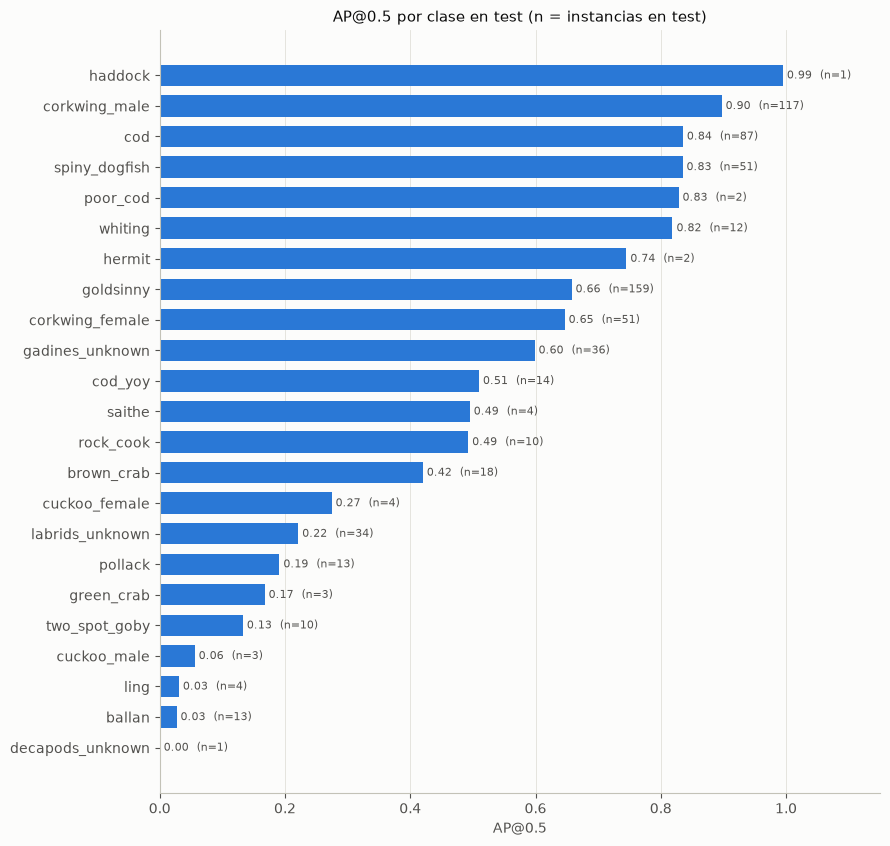

In [13]:
barras = por_clase.sort_values(["mAP50", "Instances"])
fig, ax = plt.subplots(figsize=(9, 0.32 * len(barras) + 1.2))
ax.barh(barras.Class, barras.mAP50, height=0.7, color=AZUL)
for yi, (v, n) in enumerate(zip(barras.mAP50, barras.Instances)):
    ax.text(v, yi, f" {v:.2f}  (n={n})", va="center", fontsize=8, color="#52514e")
ax.set_xlim(0, 1.15)
ax.set_xlabel("AP@0.5")
ax.set_title("AP@0.5 por clase en test (n = instancias en test)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(DIR_RESULTADOS / "ap50_por_clase_test.png", dpi=150, bbox_inches="tight")
plt.show()

Matriz de confusión normalizada y curva precisión-recall que genera Ultralytics para test.

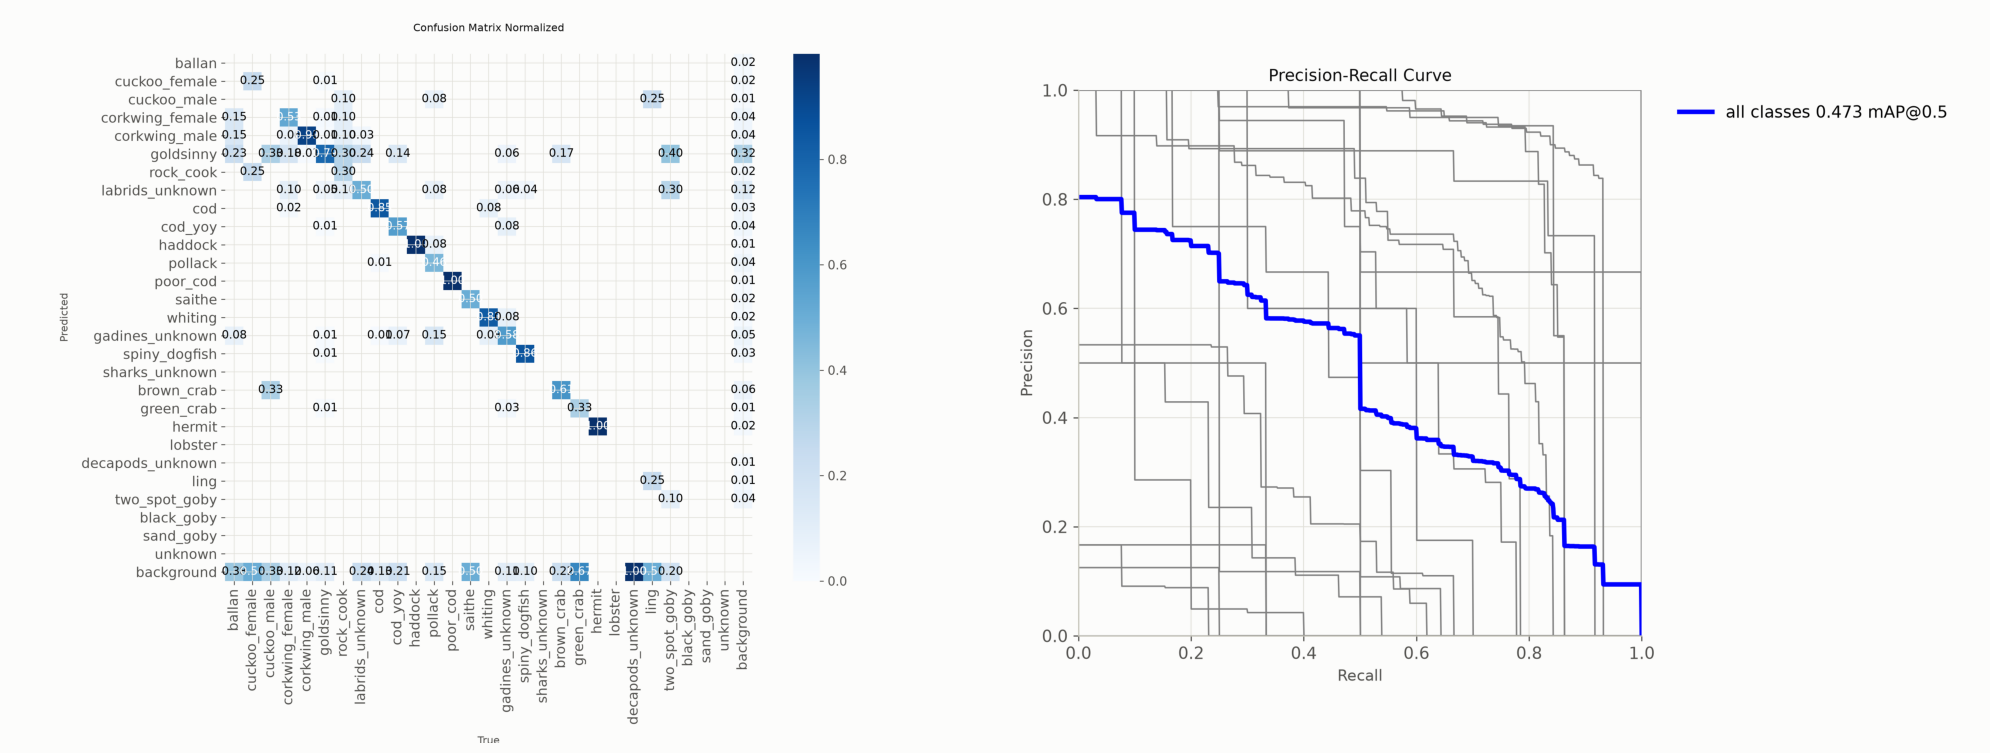

Gráficos de test en: C:\Users\rslat\tarea2_runs_80_10_10\reales\yolo_preentrenado\evaluacion_test-2


In [14]:
# Matriz de confusión normalizada y curva precisión-recall generadas por Ultralytics para test
dir_test = Path(met["test"].save_dir)
fig, axes = plt.subplots(1, 2, figsize=(20, 9))
for ax, archivo in zip(axes, ["confusion_matrix_normalized.png", "BoxPR_curve.png"]):
    ax.imshow(Image.open(dir_test / archivo))
    ax.axis("off")
fig.tight_layout()
plt.show()
print("Gráficos de test en:", dir_test)

## 8. Eficiencia: tamaño del modelo y velocidad de inferencia

Parámetros y GFLOPs (de la sección 3), tamaño del archivo de pesos y velocidad con **lote de 1 imagen** sobre imágenes de test, después de un calentamiento. La medición usa un lienzo de 640×640, igual que los otros modelos. El tiempo se separa en preprocesamiento, inferencia y postprocesamiento (NMS). Como referencia también se reporta el tiempo de inferencia por imagen al evaluar test en lotes (`ms_inferencia_en_lote`).

In [15]:
imgs_test = sorted((DATA_YAML.parent / datos["test"]).glob("*.jpg"))
args_pred = dict(imgsz=HIPERPARAMETROS["imgsz"], device=DISPOSITIVO, verbose=False, rect=False, conf=UMBRAL_CONFIANZA)   # lienzo de 640×640 y umbral común, igual que 01 y 04

for ruta in imgs_test[:10]:                       # calentamiento
    mejor.predict(ruta, **args_pred)
tiempos = pd.DataFrame([mejor.predict(ruta, **args_pred)[0].speed for ruta in imgs_test[:N_IMAGENES_VELOCIDAD]])
ms_total = float(tiempos.sum(axis=1).mean())

eficiencia = {
    "parametros_M": n_parametros / 1e6,
    "GFLOPs": gflops,
    "tamano_pesos_MB": PESOS.stat().st_size / 1e6,
    "ms_preproceso": float(tiempos.preprocess.mean()),
    "ms_inferencia": float(tiempos.inference.mean()),
    "ms_postproceso": float(tiempos.postprocess.mean()),
    "ms_total_por_imagen": ms_total,
    "FPS": 1000 / ms_total,
    "ms_inferencia_en_lote": float(met["test"].speed["inference"]),   # evaluación de test con lote = batch
}
pd.Series(eficiencia).round(3).to_frame("valor")

,valor
parametros_M,3.145
GFLOPs,8.785
tamano_pesos_MB,6.546
ms_preproceso,1.507
ms_inferencia,7.589
ms_postproceso,1.612
ms_total_por_imagen,10.708
FPS,93.385
ms_inferencia_en_lote,2.647


## 9. Resultados cualitativos

Imágenes de test elegidas al azar (semilla fija): anotación real a la izquierda y predicción a la derecha (confianza ≥ `UMBRAL_CONFIANZA`).

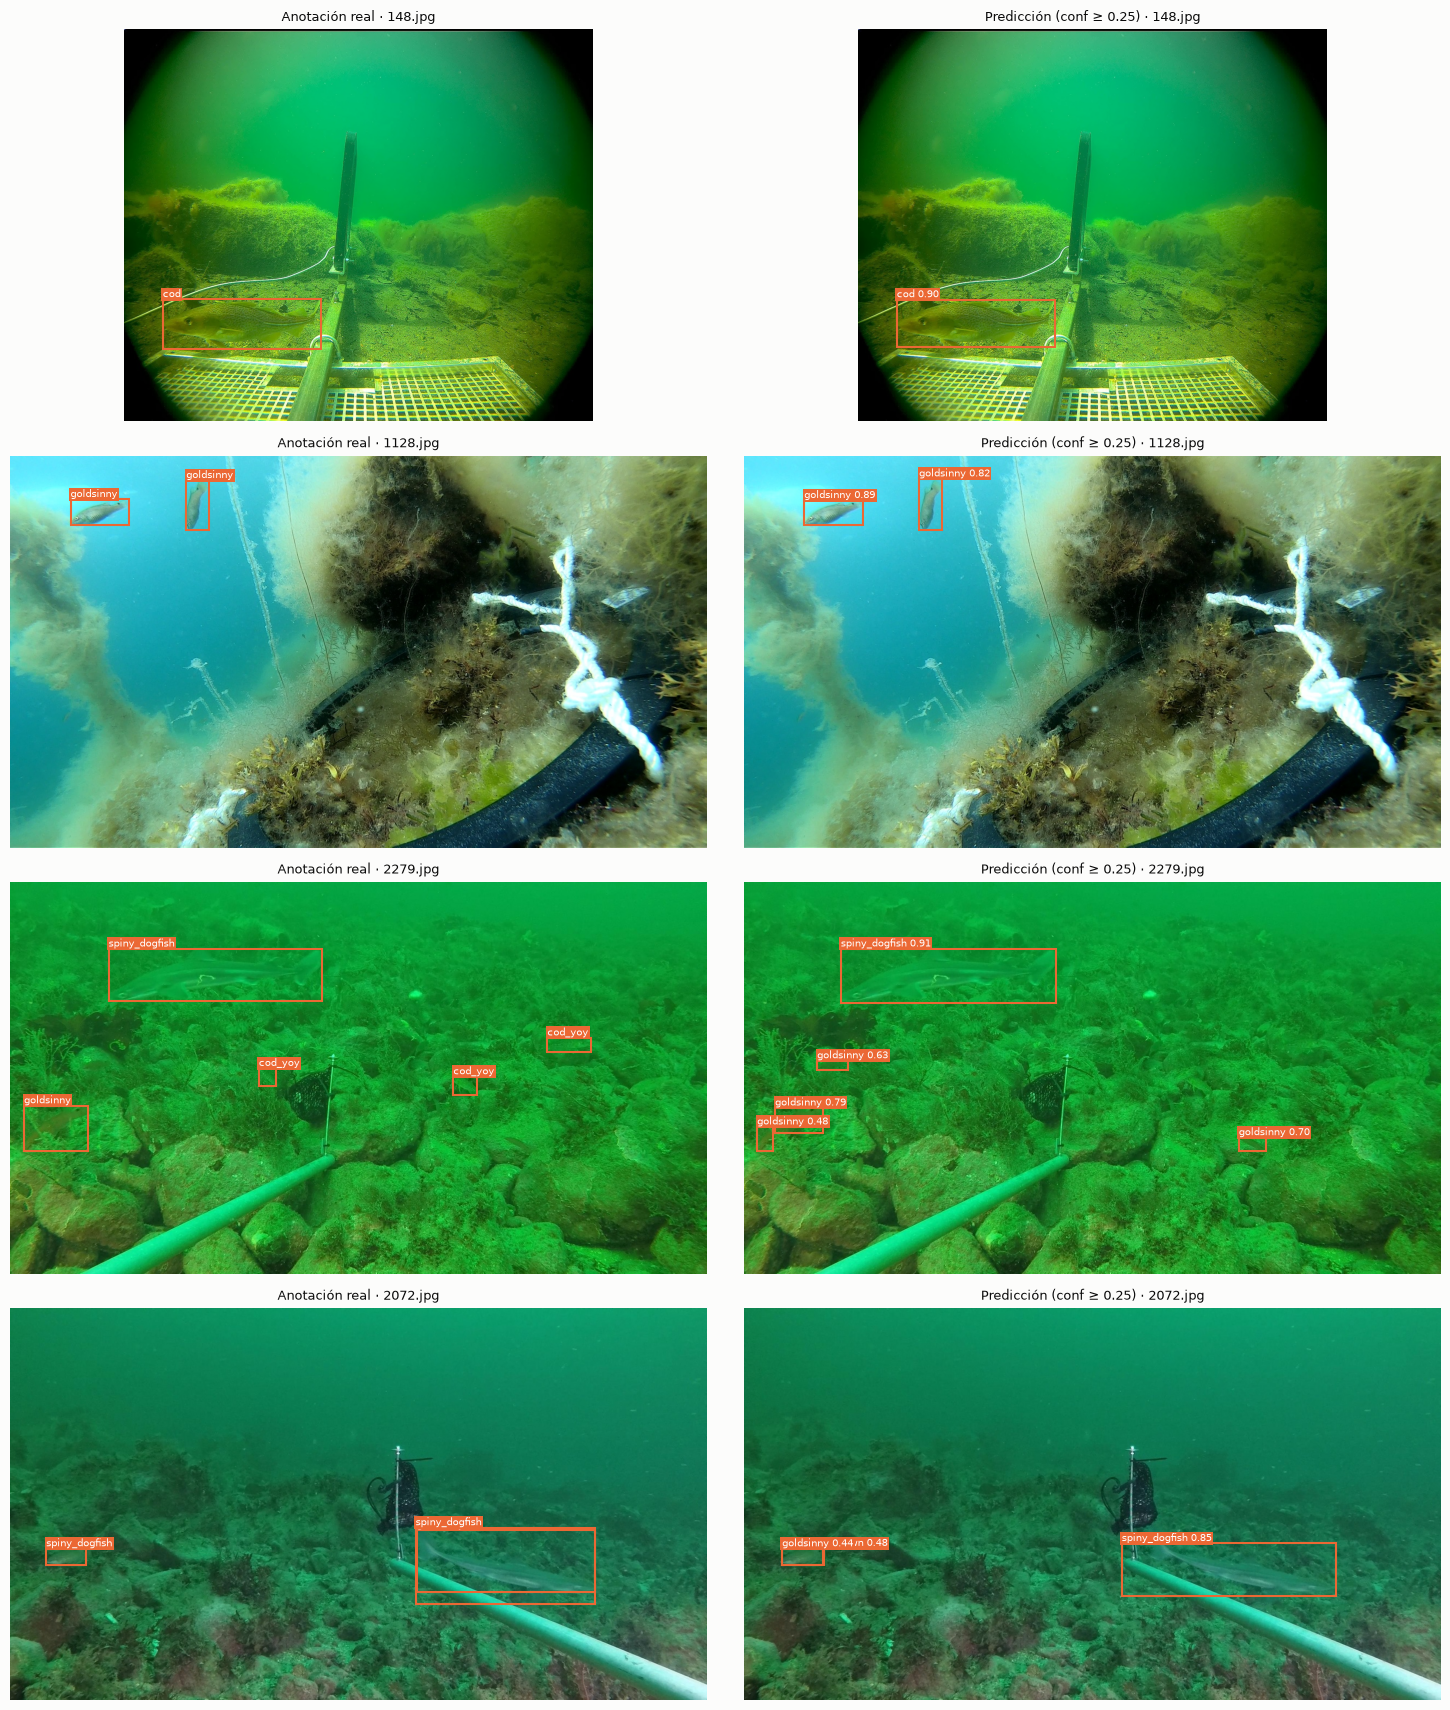

In [16]:
def dibujar(ax, img, cajas, titulo):
    ax.imshow(img)
    ax.set_title(titulo, fontsize=9)
    ax.axis("off")
    for c, x1, y1, x2, y2, conf in cajas:
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec=NARANJA, lw=1.5))
        texto = NOMBRES[c] if conf is None else f"{NOMBRES[c]} {conf:.2f}"
        ax.text(x1, y1, texto, color="white", fontsize=7, va="top" if y1 < 0.05 * img.height else "bottom",
                bbox=dict(fc=NARANJA, ec="none", pad=1), clip_on=True)


ejemplos = random.Random(SEMILLA).sample(imgs_test, N_EJEMPLOS)
fig, axes = plt.subplots(N_EJEMPLOS, 2, figsize=(15, 4.3 * N_EJEMPLOS))
for (ax_gt, ax_pred), ruta in zip(axes, ejemplos):
    img = Image.open(ruta)
    W, H = img.size
    gt = np.loadtxt(DATA_YAML.parent / "labels" / "test" / f"{ruta.stem}.txt", ndmin=2)
    cajas_gt = [(int(c), (x - w / 2) * W, (y - h / 2) * H, (x + w / 2) * W, (y + h / 2) * H, None) for c, x, y, w, h in gt]
    pred = mejor.predict(ruta, **args_pred)[0].boxes
    cajas_pred = [(int(c), *xyxy, conf) for c, xyxy, conf in zip(pred.cls.tolist(), pred.xyxy.tolist(), pred.conf.tolist())]
    dibujar(ax_gt, img, cajas_gt, f"Anotación real · {ruta.name}")
    dibujar(ax_pred, img, cajas_pred, f"Predicción (conf ≥ {UMBRAL_CONFIANZA}) · {ruta.name}")
fig.tight_layout()
fig.savefig(DIR_RESULTADOS / "ejemplos_test.png", dpi=120, bbox_inches="tight")
plt.show()

## 10. Predicciones de validación y test

Se guardan en `predicciones_val.csv` y `predicciones_test.csv` las mismas detecciones con que Ultralytics calculó el mAP de la sección 7: confianza ≥ 0,001, NMS **multietiqueta** con IoU 0,5 (una caja puede dar una detección por cada clase que supere el umbral) y hasta 300 por imagen, con coordenadas en píxeles de las imágenes de `datasets/fjordfish/images/<partición>`. La CNN propia y Faster R-CNN listan sus detecciones con este mismo protocolo, que cambia el mAP: con NMS de una sola etiqueta, como hace `predict`, el mismo modelo obtiene un mAP menor. Es el formato común de todos los modelos: con estos archivos el evaluador común calcula las métricas sin volver a ejecutar el modelo.

In [17]:
def predicciones_de_la_evaluacion(split):
    """Las detecciones que usó Ultralytics para su mAP en la sección 7, en el formato común (px de la imagen)."""
    archivo = Path(met[split].save_dir) / "predictions.json"
    detecciones = json.loads(archivo.read_text(encoding="utf-8")) if archivo.exists() else []   # sin detecciones no se escribe
    # Ultralytics guarda la caja como x, y (esquina superior izquierda), ancho y alto, y la clase sumándole 1
    filas = [(str(d["image_id"]), d["category_id"] - 1, d["score"], d["bbox"][0], d["bbox"][1],
              d["bbox"][0] + d["bbox"][2], d["bbox"][1] + d["bbox"][3]) for d in detecciones]
    return pd.DataFrame(filas, columns=["id", "clase_id", "confianza", "x1", "y1", "x2", "y2"])


predicciones = {}
for split in ("val", "test"):
    predicciones[split] = predicciones_de_la_evaluacion(split)
    predicciones[split].to_csv(DIR_RESULTADOS / f"predicciones_{split}.csv", index=False)
    print(f"{split}: {len(predicciones[split])} detecciones en {predicciones[split].id.nunique()} imágenes")

val: 2700 detecciones en 301 imágenes
test: 3222 detecciones en 301 imágenes


## 11. Métricas con el evaluador común

Se calculan el mAP50, el mAP75 y el mAP50-95 con el evaluador común de `comun.py` (el mismo que usa `05_comparacion.ipynb` para todos los modelos) a partir de las predicciones de la sección 10, que son exactamente las que usó Ultralytics, y se comparan con las de la sección 7. Así se comprueba que el evaluador común está bien: la diferencia debería ser de milésimas, porque ambos siguen la definición de COCO y solo difieren en detalles (Ultralytics empareja predicciones y cajas reales por IoU en vez de por confianza, e integra la curva precisión-recall con trapecios).

La precisión, el recall y el F1 con el umbral común (D8) se calculan en `05_comparacion.ipynb`, una vez que el grupo elija el umbral.

In [18]:
filas = []
for split in ("val", "test"):
    reales = cargar_cajas_reales(DIR_DATASET, split, particion[split])
    propio = evaluar_detecciones(predicciones[split], reales, nombres=NOMBRES)
    de_ultralytics = resumen_metricas(met[split])
    for metrica in ("mAP50", "mAP75", "mAP50_95"):
        filas.append({"partición": split, "métrica": metrica,
                      "evaluador común": propio[metrica], "Ultralytics": de_ultralytics[metrica]})
tabla_evaluadores = pd.DataFrame(filas)
tabla_evaluadores["diferencia"] = tabla_evaluadores["evaluador común"] - tabla_evaluadores["Ultralytics"]
tabla_evaluadores.to_csv(DIR_RESULTADOS / "evaluador_comun_vs_ultralytics.csv", index=False)
tabla_evaluadores.round(4)

,partición,métrica,evaluador común,Ultralytics,diferencia
0,val,mAP50,0.4955,0.4940,0.0015
1,val,mAP75,0.3995,0.3978,0.0017
2,val,mAP50_95,0.3620,0.3602,0.0018
3,test,mAP50,0.4757,0.4728,0.0029
4,test,mAP75,0.3799,0.3762,0.0037
5,test,mAP50_95,0.3420,0.3388,0.0031


## 12. Resumen para la comparación

Métricas de esta corrida en `resultados/yolo_preentrenado/resumen.json` y `resumen.csv`, con las mismas claves que los otros modelos más los parámetros congelados y entrenables, junto con `historial.csv` (columnas comunes por época).

Las métricas de este resumen son las de Ultralytics: la precisión y el recall están al umbral que maximiza el F1. `05_comparacion.ipynb` recalcula todas las métricas de todos los modelos con el evaluador común y el umbral común (D8), a partir de las predicciones de la sección 10.

In [19]:
historial = pd.DataFrame({
    "epoca": hist.epoch,
    "tiempo_s": hist.time,                    # tiempo acumulado desde el inicio del entrenamiento
    "perdida_train": hist[["train/box_loss", "train/cls_loss", "train/dfl_loss"]].sum(axis=1),
    "perdida_val": hist[["val/box_loss", "val/cls_loss", "val/dfl_loss"]].sum(axis=1),
    "val_mAP50": hist["metrics/mAP50(B)"],
    "val_mAP50_95": hist["metrics/mAP50-95(B)"],
})
historial.to_csv(DIR_RESULTADOS / "historial.csv", index=False)

resumen = {
    "modelo": f"YOLO preentrenado ({Path(MODELO_YAML).stem}, COCO)",
    "huella_particion": huella,
    "epocas_ejecutadas": epocas_ejecutadas,
    "mejor_epoca": mejor_epoca,
    "tiempo_entrenamiento_min": info_entrenamiento["tiempo_entrenamiento_s"] / 60,
    "tiempo_por_epoca_s": tiempo_por_epoca_s,
    "memoria_gpu_max_GB": info_entrenamiento["memoria_gpu_max_GB"],
    **{f"test_{k}": v for k, v in resumen_metricas(met["test"]).items()},
    **{f"val_{k}": v for k, v in resumen_metricas(met["val"]).items()},
    **eficiencia,
    "parametros_entrenables_M": tabla_componentes.loc["Total", "entrenables"] / 1e6,
    "parametros_congelados_M": tabla_componentes.loc["Total", "congelados"] / 1e6,
}
(DIR_RESULTADOS / "resumen.json").write_text(json.dumps(resumen, indent=2, ensure_ascii=False), encoding="utf-8")
pd.Series(resumen).to_frame("valor").to_csv(DIR_RESULTADOS / "resumen.csv")
pd.Series(resumen).to_frame("valor")

,valor
modelo,"YOLO preentrenado (yolov8n, COCO)"
huella_particion,84ea7ae5b688
epocas_ejecutadas,300
mejor_epoca,272
tiempo_entrenamiento_min,88.725
tiempo_por_epoca_s,17.6923
memoria_gpu_max_GB,2.67
test_precision,0.546062
test_recall,0.451614
test_F1,0.494368


## 13. ✍️ Justificación de las decisiones (completar por el grupo)

> La tarea pide justificar estas decisiones con argumentos propios del grupo; el uso de IA generativa para diseñar la solución o analizar resultados está prohibido.

- **Qué se congeló, qué se entrenó y por qué *fine-tuning* completo**:
- **Elección de `yolov8n`**:
- **Hiperparámetros y tasa de aprendizaje**:
- **Número de épocas y parada temprana**:
- **Aumento de datos**:

## 14. ✍️ Análisis de resultados (completar por el grupo)

-

## ✍️ Declaración de uso de IA generativa

> Completar según lo que pide la tarea (herramienta y propósito específico).